In [1]:
import torch
import torch.nn as nn
import sys
sys.path.append('..')
import cying.nn as cynn

In [15]:
bsplin = cynn.BSpline1D(
    1,
    degree=3
)

In [16]:
x = torch.linspace(0,1,100)
y = bsplin.basis(x)

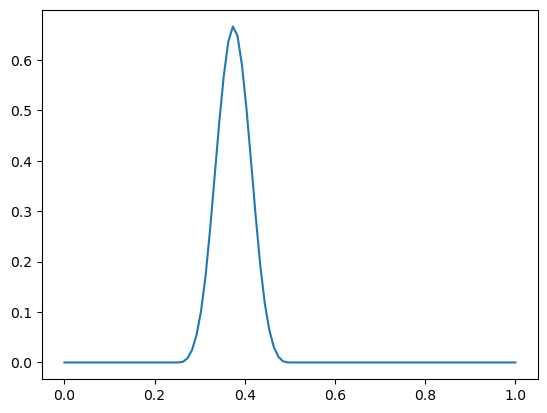

In [25]:
import matplotlib.pyplot as plt
plt.plot(x.numpy(), y.detach().numpy()[:,7])

In [18]:
y[:,0]

tensor([1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000,
        1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000,
        1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000,
        1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000],
       grad_fn=<SelectBackward0>)

In [20]:
x

tensor([0.0000, 0.0312, 0.0625, 0.0938, 0.1250, 0.1562, 0.1875, 0.2188, 0.2500,
        0.2812, 0.3125, 0.3438, 0.3750, 0.4062, 0.4375, 0.4688, 0.5000, 0.5312,
        0.5625, 0.5938, 0.6250, 0.6562, 0.6875, 0.7188, 0.7500, 0.7812, 0.8125,
        0.8438, 0.8750, 0.9062, 0.9375, 0.9688, 1.0000])

In [ ]:
import numpy as np

def bspline_basis(i, p, t, knots):
    if p == 0:
        return 1.0 if knots[i] <= t < knots[i+1] else 0.0

    denom1 = knots[i+p] - knots[i]
    denom2 = knots[i+p+1] - knots[i+1]

    left = 0.0
    if denom1 > 0:
        left = (t - knots[i]) / denom1 * bspline_basis(i, p-1, t, knots)

    right = 0.0
    if denom2 > 0:
        right = (knots[i+p+1] - t) / denom2 * bspline_basis(i+1, p-1, t, knots)

    return left + right


def bspline_curve(control_points, p, n_samples=100, clamped=True):
    """
    根据控制点生成 B 样条曲线。
    control_points : (n, dim) 数组
    p              : 次数
    n_samples      : 采样点数
    clamped        : 是否使用 clamped 节点向量（曲线过首尾点）
    """
    control_points = np.asarray(control_points, dtype=float)
    n = len(control_points)

    # 构造节点向量
    if clamped:
        # clamped: 首尾各重复 p+1 次
        knots = np.concatenate([
            np.zeros(p+1),
            np.linspace(0, 1, n - p + 1)[1:-1],
            np.ones(p+1)
        ])
    else:
        # 均匀节点
        knots = np.linspace(0, 1, n + p + 1)

    t_values = np.linspace(knots[p], knots[n], n_samples)
    curve = []

    for t in t_values:
        pt = np.zeros(control_points.shape[1])
        for i in range(n):
            pt += bspline_basis(i, p, t, knots) * control_points[i]
        curve.append(pt)

    return np.array(curve), knots

/home/wangh/miniconda3/envs/torch/lib/python3.13/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 25511 (\N{CJK UNIFIED IDEOGRAPH-63A7}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/home/wangh/miniconda3/envs/torch/lib/python3.13/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 21046 (\N{CJK UNIFIED IDEOGRAPH-5236}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/home/wangh/miniconda3/envs/torch/lib/python3.13/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 22810 (\N{CJK UNIFIED IDEOGRAPH-591A}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/home/wangh/miniconda3/envs/torch/lib/python3.13/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 36793 (\N{CJK UNIFIED IDEOGRAPH-8FB9}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/home/wangh/miniconda3/envs/torch/lib/python3.13/site-packages/IPython/core/pylabtoo

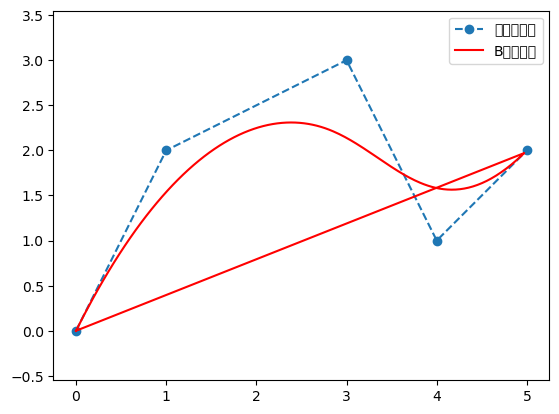

In [15]:
# 控制点
ctrl = np.array([
    [0, 0],
    [1, 2],
    [3, 3],
    [4, 1],
    [5, 2],
])

curve, knots = bspline_curve(ctrl, p=3, n_samples=200)

# 可视化
import matplotlib.pyplot as plt
plt.plot(ctrl[:,0], ctrl[:,1], 'o--', label='控制多边形')
plt.plot(curve[:,0], curve[:,1], 'r-', label='B样条曲线')
plt.legend(); plt.axis('equal'); plt.show()